# Autoencoders on Fashion MNIST

**Goal:**
- Load and visualize the Fashion MNIST dataset.
- Build an Autoencoder using convolutional layers.
- Train the Autoencoder and evaluate its performance.
- Extract and visualize latent space embeddings.
- Reconstruct images and generate new ones.

## 1. Load and Visualize the Dataset

### 1.1: Import Necessary Libraries

Useful transformations when working with images:
- **Padding**: to resize images (e.g., 28×28 → 32×32)
- **ToTensor**: converts PIL images to PyTorch tensors and normalizes pixel values to [0, 1]
- **Normalize**: standardizes pixel values using mean and std
- **RandomHorizontalFlip / RandomRotation**: data augmentation to improve generalization

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

### 1.2: Prepare the Data

In [2]:
# Preprocessing
transform = transforms.Compose([
    transforms.Pad(2),        # Pad 28x28 images to 32x32
    transforms.ToTensor(),    # Convert images to tensors (values in [0, 1])
])

batch_size = 128

# Load data
train_dataset = datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size, shuffle=True)

val_dataset = datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)
val_loader = DataLoader(val_dataset, batch_size, shuffle=False)

100%|██████████| 26.4M/26.4M [00:00<00:00, 53.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 2.10MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 29.5MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.7MB/s]


### 1.3: Visualizing Sample Images

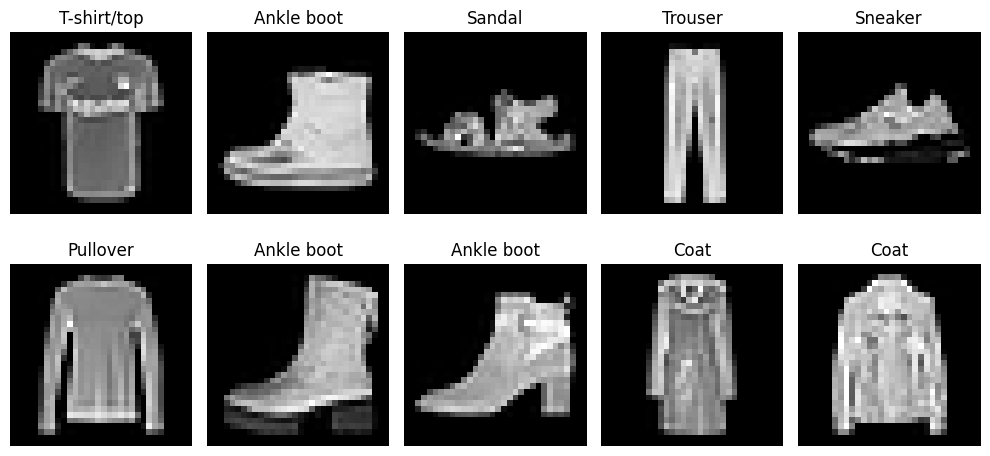

In [3]:
class_labels = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

def plot_sample_images(loader):
    data_iter = iter(loader)
    images, labels = next(data_iter)
    images = images.numpy()

    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(class_labels[labels[i].item()])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(train_loader)

## 2. Build the Autoencoder

An **Autoencoder** consists of two parts:
1. **Encoder**: Reduces the input image to a compressed representation (latent space).
2. **Decoder**: Reconstructs the original image from the compressed representation.

### 2.1: Define the Autoencoder Model
We use **convolutional layers** for encoding and **transposed convolution layers** for decoding.

### 2.2: Define the Latent Space

**Question — How does reducing the dimensionality help the model?**  
Reducing dimensionality forces the model to learn the most essential features of the data, eliminating noise and redundancies. It acts as an information bottleneck that compels the encoder to capture meaningful, compact representations.

**What happens if the latent space is too small or too large?**  
- **Too small**: The model cannot capture enough information → poor reconstructions, underfitting.  
- **Too large**: The model may memorize the input without learning useful structure → no compression, potential overfitting.

In [4]:
# Define the Autoencoder Model
class Autoencoder(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        """
        Initialize the Autoencoder model.
        - input_shape: The shape of the input images (1, 32, 32) for grayscale images.
        - latent_dim: The number of neurons in the latent space.
        """
        super(Autoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            # First convolutional layer: Convert 1-channel input into 32 feature maps.
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            # Second convolutional layer: Reduce spatial dimensions further.
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            # Third convolutional layer: Extract higher-level features.
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )

        # Dynamically calculate the flattened size after encoding
        flattened_size, decode_shape = self.calculate_flattened_size(self.encoder, input_shape)

        # Latent space (fully connected layer)
        self.fc = nn.Sequential(
            nn.Flatten(start_dim=1),              # Flatten the encoded features
            nn.Linear(flattened_size, latent_dim) # Compress to latent dimension
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flattened_size),             # Map latent space back to the feature map
            nn.Unflatten(decode_shape[0], decode_shape[1:]),   # Reshape to match the encoded feature map
            # Transposed Convolution layers (Decoder)
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            # Final deconvolution layer: Convert back to single-channel grayscale image
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()  # Output values between 0 and 1
        )

    def calculate_flattened_size(self, model, input_shape):
        """
        Helper function to determine the flattened size after the encoder.
        Returns the flattened size (number of features) and output shape.
        """
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
            return output.numel(), output.shape

    def forward(self, x):
        """
        Forward pass through the Autoencoder.
        Returns reconstructed image and latent space representation.
        """
        x = self.encoder(x)   # Pass through the encoder
        latent = self.fc(x)   # Project into latent space
        x = self.decoder(latent)  # Decode the latent representation
        return x, latent

In [5]:
# Test dimension consistency
x_sample = torch.randn(1, 1, 32, 32)
model_test = Autoencoder()
image_test, latent_space = model_test(x_sample)
assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"
print(f"Input shape:   {x_sample.shape}")
print(f"Output shape:  {image_test.shape}")
print(f"Latent shape:  {latent_space.shape}")
print("Dimension test passed!")

Input shape:   torch.Size([1, 1, 32, 32])
Output shape:  torch.Size([1, 1, 32, 32])
Latent shape:  torch.Size([1, 2])
Dimension test passed!


## 3. Train the Autoencoder

### 3.1: Define the Training Process
- **Optimizer**: Adam with lr = 0.0001
- **Loss function**: MSELoss (reconstruction error)

### 3.2: Evaluate the Model
- Compute MSE loss and Binary Cross-Entropy on validation set

In [6]:
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


def evaluate_model(model, loader):
    """
    Evaluate the model on validation data.
    Returns avg_loss (MSE) and avg cross-entropy loss.
    """
    model.eval()
    total_loss = 0
    loss_fn = nn.MSELoss()
    ce_losss = 0

    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)
            recon_x, _ = model(x)
            loss = loss_fn(recon_x, x)
            ce_loss = F.binary_cross_entropy(recon_x, x)
            total_loss += loss.item()
            ce_losss += ce_loss

    avg_loss = total_loss / len(loader.dataset)
    ce_losss /= len(loader.dataset)
    return avg_loss, ce_losss


def plot_training_loss(train_losses, val_losses):
    """Plot the training and validation loss across epochs."""
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss", marker="o")
    plt.plot(val_losses, label="Validation Loss", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()


def train_model(model, train_loader, val_loader, epochs):
    """
    Train the Autoencoder model.
    - model: The Autoencoder instance.
    - train_loader: DataLoader for training data.
    - val_loader: DataLoader for validation data.
    - epochs: Number of training iterations.
    """
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    loss_fn = nn.MSELoss()

    print("Start Training...")
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        tqdm_loader = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

        for x, _ in tqdm_loader:
            x = x.to(device)
            recon_x, _ = model(x)
            loss = loss_fn(recon_x, x)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / len(train_loader.dataset)
        avg_val_loss, ce_losss = evaluate_model(model, val_loader)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        print(f"Epoch [{epoch + 1}/{epochs}], "
              f"Train Loss: {100*avg_train_loss:.6f} %, "
              f"Val Loss: {100*avg_val_loss:.6f} %, "
              f"Val Loss cross_entropy: {100*ce_losss:.6f} %")

    plot_training_loss(train_losses, val_losses)

Using device: cpu


Start Training...


Evaluating: 100%|██████████| 79/79 [00:01<00:00, 50.26it/s]


Epoch [1/20], Train Loss: 0.054686 %, Val Loss: 0.031536 %, Val Loss cross_entropy: 0.246095 %


Evaluating: 100%|██████████| 79/79 [00:01<00:00, 47.20it/s]


Epoch [2/20], Train Loss: 0.027653 %, Val Loss: 0.026108 %, Val Loss cross_entropy: 0.232971 %


...

Epoch [18/20], Train Loss: 0.020421 %, Val Loss: 0.020575 %, Val Loss cross_entropy: 0.211497 %


Evaluating: 100%|██████████| 79/79 [00:02<00:00, 38.37it/s]


Epoch [19/20], Train Loss: 0.020306 %, Val Loss: 0.020581 %, Val Loss cross_entropy: 0.211346 %


Evaluating: 100%|██████████| 79/79 [00:02<00:00, 38.33it/s]


Epoch [20/20], Train Loss: 0.020195 %, Val Loss: 0.020420 %, Val Loss cross_entropy: 0.210808 %


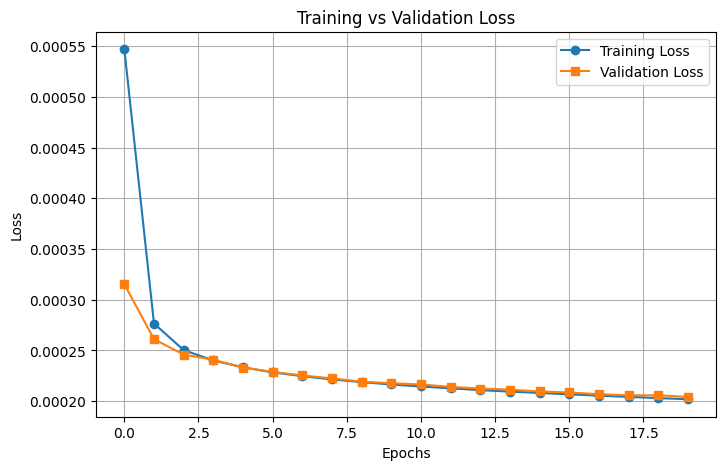

In [7]:
# Instantiate and train the model
autoencoder = Autoencoder()
train_model(autoencoder, train_loader, val_loader, epochs=20)

## 4. Reconstruct Images Using the Autoencoder

### 4.1: Extract a Few Test Images
### 4.2: Compare Original vs Reconstructed Images

**How could you improve the model to get sharper images?**  
- Increase the latent dimension (e.g., 16, 64, 128) to capture more detail
- Add more convolutional layers or increase the number of filters
- Use Perceptual Loss (feature-based) instead of pure MSE
- Train for more epochs with learning rate scheduling
- Use Batch Normalization to stabilize training

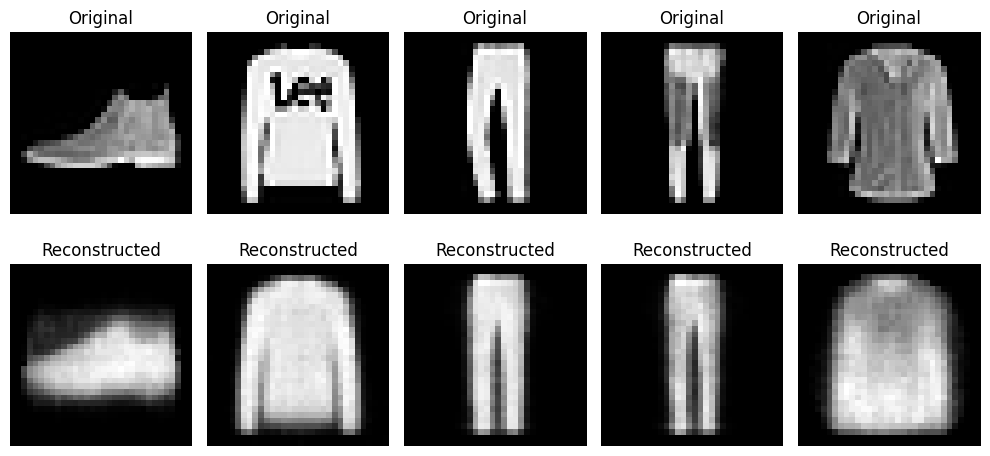

In [8]:
# Function to plot reconstructions
def plot_reconstructions(model, loader, ex=True):
    model.eval()
    model = model.to("cpu")

    with torch.no_grad():
        if ex:
            for x, _ in loader:
                recon_x, _ = model(x)
                break
        else:
            x = loader
            recon_x = model.decoder(x)

    x = x.cpu().numpy()
    recon_x = recon_x.cpu().numpy()

    plt.figure(figsize=(10, 5))
    for i in range(5):
        if ex:
            plt.subplot(2, 5, i + 1)
            plt.imshow(x[i].squeeze(), cmap="gray")
            plt.title("Original")
            plt.axis("off")

        plt.subplot(2, 5, i + 6)
        plt.imshow(recon_x[i].squeeze(), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_reconstructions(autoencoder, val_loader)

## 5. Visualize the Latent Space

### 5.1: Extract Embeddings

In [9]:
# Initialize lists to store embeddings and corresponding labels
embeddings = []
labels = []

# Move the Autoencoder to the appropriate device
autoencoder = autoencoder.to(device)

# Disable gradient computation for efficiency
with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        _, latent = autoencoder(x)  # Extract latent space embeddings
        embeddings.append(latent.cpu().numpy())
        labels.append(y.numpy())

# Combine embeddings and labels into single arrays
embeddings = np.concatenate(embeddings, axis=0)
labels = np.concatenate(labels, axis=0)

# Identify unique class labels
unique_labels = np.unique(labels)
autoencoder = autoencoder.to("cpu")

print(f"Embeddings shape: {embeddings.shape}")
print(f"Labels shape: {labels.shape}")

Embeddings shape: (60000, 2)
Labels shape: (60000,)


### 5.2: Plot in a 2D Space

**Would images of similar clothing types cluster together and are they well represented?**  
With a 2D latent space, some clustering is visible but classes often overlap due to the very low dimensionality. The bottleneck is too tight to perfectly separate all 10 categories. Increasing the latent dimension (e.g., to 16 or 32) would yield better-separated clusters.

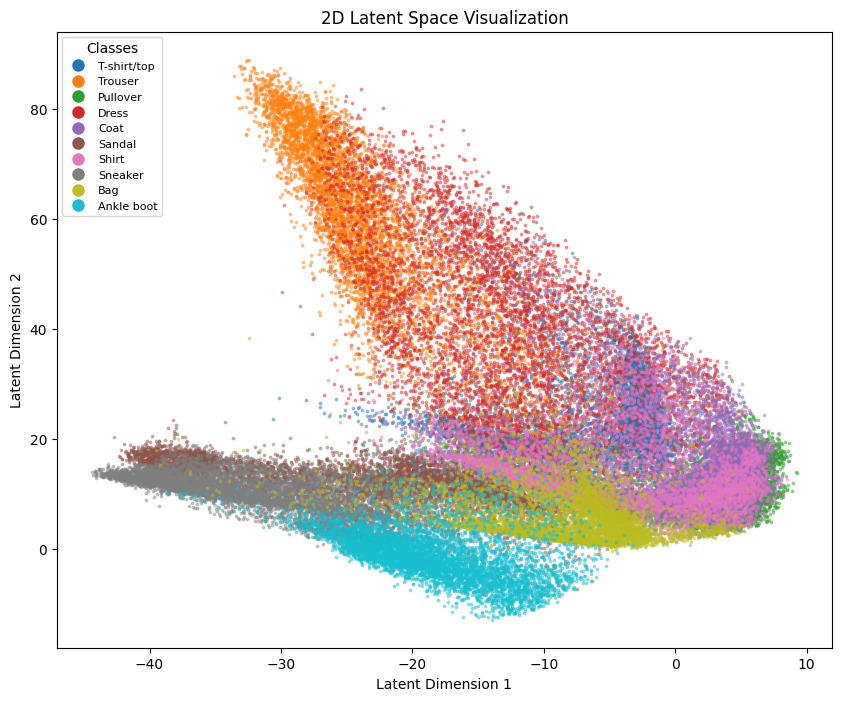

In [10]:
# Plot the 2D embeddings
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

plt.figure(figsize=(10, 8))
legend_handles = []

for i, label in enumerate(unique_labels):
    indices = np.where(labels == label)[0]
    scatter = plt.scatter(
        embeddings[indices, 0], embeddings[indices, 1],
        c=[colors[i]], alpha=0.4, s=3, label=class_labels[label]
    )
    legend_handles.append(
        Line2D([0], [0], marker='o', color='w', label=f'{class_labels[label]}',
               markersize=10, markerfacecolor=colors[i])
    )

plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.title('2D Latent Space Visualization')
plt.legend(handles=legend_handles, title='Classes', loc='upper left', fontsize=8)
plt.show()

## 6. Generate New Images Using the Decoder

### 6.1: Sample Random Points in Latent Space
### 6.2: Plot Generated Images

**Are there any objects not well reconstructed?**  
Yes — with a 2D latent space, fine-grained items like shirts, pullovers, and coats tend to be poorly reconstructed since they share overlapping features in such a compact space.

Generated Latent Samples:
 tensor([[-18.1848,  42.0504],
        [-26.0795,  79.9084],
        [-35.7258,  86.7231],
        [-39.2615,  37.2689],
        [  3.0342,  12.9829]])


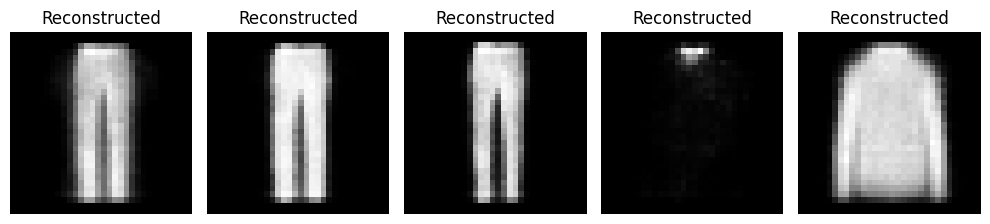

In [11]:
# Generate latent space samples for visualization
mins, maxs = np.min(embeddings, axis=0), np.max(embeddings, axis=0)
sample = torch.tensor(np.random.uniform(mins, maxs, size=(5, 2)), dtype=torch.float32)

print("Generated Latent Samples:\n", sample)

# Plot reconstructions from sampled latent space
plot_reconstructions(autoencoder, sample, ex=False)

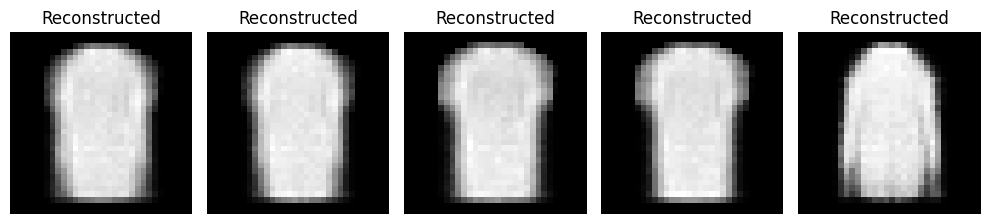

In [12]:
# Example for an ankle boot
x_sample = torch.tensor([[0., 20], [0., 25], [-2., 20], [-2., 25], [5., 30]])
plot_reconstructions(autoencoder, x_sample, ex=False)

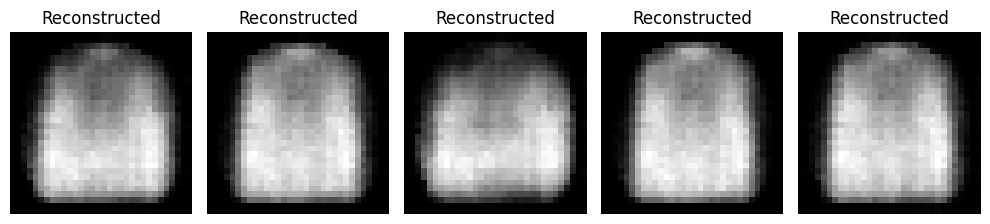

In [13]:
# Plot examples of Trouser
# Based on the latent space visualization, trousers tend to cluster in a specific region.
# Adjust these coordinates based on your own latent space plot.
trouser_sample = torch.tensor([[-5., 5.], [-4., 6.], [-6., 4.], [-5., 7.], [-3., 5.]])
plot_reconstructions(autoencoder, trouser_sample, ex=False)

In [14]:
# Save the model
torch.save(autoencoder.state_dict(), "VAmodel_state_dict.pth")
print("Model saved to VAmodel_state_dict.pth")

Model saved to VAmodel_state_dict.pth
